In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")  # repo root, so `core` is importable

from core import deempc, drmpc
from core.generate_rng import trial_rngs
from core.offline import collect_offline_trajectories
from core.radius import estimate_radius

## Setup: SAAMPC vs. DRMPC vs. DeePC on the mass-spring-damper

Same system, spec and data as `drmpc/mass_spring_damper_experiment.ipynb` (the paper-like setup: T = 5, noise 0.03, N = 10–40, 50 trials, 30 steps, |u| ≤ 10 N). All three methods see the **same offline trajectories** and the **same closed-loop noise** in each trial, via `trial_rngs(SEED, k)`, so the SAAMPC and DRMPC numbers below reproduce that notebook's Fig. 2.

| | Predicts with | Handles noise with |
|---|---|---|
| SAAMPC | least-squares L̂ + residual scenarios | nothing (radius 0) |
| DRMPC | least-squares L̂ + residual scenarios | Wasserstein radius (Algorithm 1) |
| DeePC | the trajectories themselves, blended by g | λ_g‖g‖₁ (paper eq. 8) |

Differences from the cart-pole comparison: the system is **stable** (open-loop errors decay instead of growing), the horizon is 5 not 20, and the slack weight is the default 1e6 for all three, as in the DRMPC notebook.

In [2]:
mass, k, c, dt = 1.0, 1.0, 1.0, 0.1
A = np.eye(2) + dt * np.array([[0, 1], [-k / mass, -c / mass]])
B = dt * np.array([[0.0], [1 / mass]])
n, m = A.shape[0], B.shape[1]
T = 5
STEPS = 30
NOISE = 0.03
U_MAX = 10.0
SEED = 0       # evaluation trials, same as the DRMPC notebook
TUNE_SEED = 1  # lambda_g is chosen on these trials only, never on SEED
X0 = [0.9, 0.0]
spec = dict(state_weight=[1, 0], ref=[2, 0], x_min=[-np.inf, -np.inf], x_max=[1, np.inf])
SIZES = [10, 20, 30, 40]
COLORS = {"SAAMPC": "#2a78d6", "DRMPC": "#eb6834", "DeePC": "#3a9e5c"}


def dataset(num_trajectories, rng):
    return collect_offline_trajectories(A, B, num_trajectories, T, noise_std=NOISE, action_std=5.0, rng=rng)


def closed_loop(make, W):
    """Run make() from X0 under W; None if a solve fails."""
    try:
        return drmpc.simulate(A, B, make(), X0, W)
    except RuntimeError:
        return None


def run_drmpc(L_hat, Z, Y, eps1, eps2, W):
    return closed_loop(lambda: drmpc.make_controller(L_hat, Z, Y, n, m, eps1, eps2, u_max=U_MAX, **spec), W)


def run_deepc(Z, Y, lambda_g, W):
    return closed_loop(lambda: deempc.make_controller(Z, Y, n, lambda_g, u_max=U_MAX, **spec), W)


def metrics(result):
    return (np.nan, np.nan) if result is None else drmpc.closed_loop_metrics(result[0], **spec)

## Data check: does the fundamental lemma hold?

DeePC needs rank [X0; U_f] = n + mT = 2 + 5 = 7. At N = 10 that leaves only 3 spare columns, far fewer than the cart-pole's 11 at N = 35.

In [3]:
for N in SIZES:
    Z, _ = dataset(N, trial_rngs(SEED, 0)[0])
    rank, needed = deempc.fundamental_lemma_rank(Z) # If this is not satisfied, u can be forced to 0.
    print(f"N={N:<3}: rank {rank} of {needed} needed, {N - needed} spare columns")

N=10 : rank 7 of 7 needed, 3 spare columns
N=20 : rank 7 of 7 needed, 13 spare columns
N=30 : rank 7 of 7 needed, 23 spare columns
N=40 : rank 7 of 7 needed, 33 spare columns


## Choosing λ_g on a separate seed

λ_g has no formula like DRMPC's Algorithm 1, so it is picked from a grid on `TUNE_SEED` trials. Picking it on the evaluation trials would let DeePC fit their noise, which is the backtest in-sample bias from finance.

Rule: fewest mean violations, then lowest median cost. A λ_g with any failed run is excluded.

In [4]:
LAMBDAS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
TUNE_TRIALS = 10

tuning = {}
for N in SIZES:
    draws = []
    for trial in range(TUNE_TRIALS):
        rng_data, rng_noise = trial_rngs(TUNE_SEED, trial)
        draws.append((*dataset(N, rng_data), rng_noise.normal(0, NOISE, (STEPS, n))))
    for lam in LAMBDAS:
        tuning[N, lam] = np.array([metrics(run_deepc(Z, Y, lam, W)) for Z, Y, W in draws])


def score(r):
    costs, violations = r.T
    return (np.inf, np.inf) if np.isnan(costs).any() else (violations.mean(), np.median(costs))


LAMBDA_G = {N: min(LAMBDAS, key=lambda lam: score(tuning[N, lam])) for N in SIZES}

print("mean violations / median cost on tuning trials")
print("lambda_g " + "".join(f"{f'N={N}':>14}" for N in SIZES))
for lam in LAMBDAS:
    row = "".join(f"{'%.1f / %.1f' % score(tuning[N, lam]):>14}" for N in SIZES)
    print(f"{lam:<9}{row}")
print("chosen:", LAMBDA_G)

mean violations / median cost on tuning trials
lambda_g           N=10          N=20          N=30          N=40
0.001       14.5 / 31.2    8.2 / 41.2    8.3 / 32.2    8.2 / 36.3
0.003       14.5 / 31.2    8.2 / 41.2    8.3 / 32.2    8.2 / 36.3
0.01        14.5 / 31.2    8.2 / 41.2    8.3 / 32.2    8.1 / 36.3
0.03        14.7 / 30.4    8.2 / 35.6    8.3 / 32.2    8.1 / 36.3
0.1         15.0 / 30.6   17.1 / 30.2   13.7 / 30.7   12.4 / 29.9
0.3         15.0 / 29.9   16.0 / 30.6   16.6 / 30.7   14.6 / 30.3
1.0         11.7 / 32.3   14.0 / 30.7   12.9 / 30.6   13.1 / 30.8
chosen: {10: 1.0, 20: 0.03, 30: 0.03, 40: 0.03}


## One dataset: all three trajectories

N = 10, trial 0. Same data and noise for all three. Dashed line is the stop at 1 m, dotted is the target at 2 m.

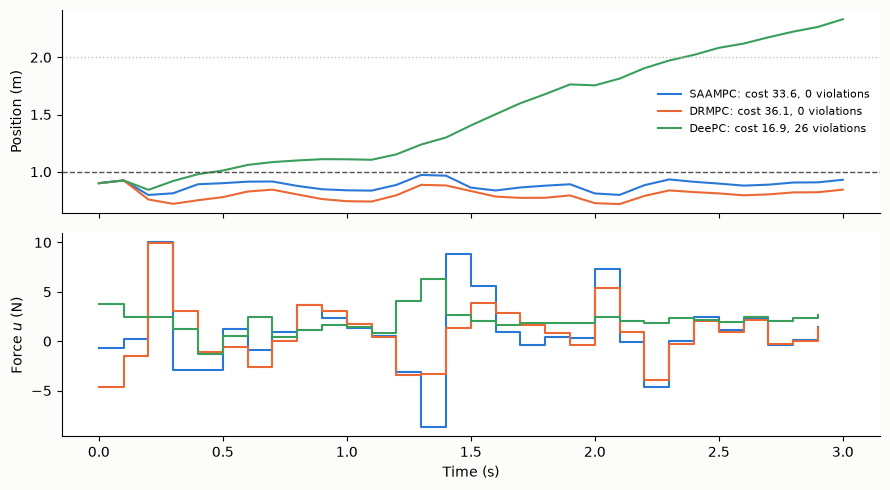

In [5]:
rng_data, rng_noise = trial_rngs(SEED, 0)
Z, Y = dataset(10, rng_data)
W = rng_noise.normal(0, NOISE, (STEPS, n))
L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
runs = {"SAAMPC": run_drmpc(L_hat, Z, Y, 0.0, 0.0, W),
        "DRMPC": run_drmpc(L_hat, Z, Y, eps1, eps2, W),
        "DeePC": run_deepc(Z, Y, LAMBDA_G[10], W)}

t = np.arange(STEPS + 1) * dt
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, facecolor="#fcfcfb")
for name, result in runs.items():
    if result is None:
        print(f"{name} failed")
        continue
    X, U = result
    cost, violations = drmpc.closed_loop_metrics(X, **spec)
    axes[0].plot(t, X[:, 0], color=COLORS[name], label=f"{name}: cost {cost:.1f}, {violations} violations")
    axes[1].step(t[:-1], U[:, 0], where="post", color=COLORS[name])
axes[0].axhline(1, color="#52514e", linestyle="--", linewidth=1)
axes[0].axhline(2, color="#c3c2b7", linestyle=":", linewidth=1)
axes[0].set_ylabel("Position (m)")
axes[1].set_ylabel("Force $u$ (N)")
axes[1].set_xlabel("Time (s)")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Comparison by dataset size

50 trials per N (as in the paper), trial k from `trial_rngs(SEED, k)`: the exact draws of the DRMPC notebook's Fig. 2. All three methods share the data and noise in each trial. DeePC uses the λ_g chosen above for that N. A run counts as failed if the solver gives up.

In [6]:
TRIALS = 50
results = {}
for N in SIZES:
    runs_n = {name: [] for name in COLORS}
    for trial in range(TRIALS):
        rng_data, rng_noise = trial_rngs(SEED, trial)
        Z, Y = dataset(N, rng_data)
        W = rng_noise.normal(0, NOISE, (STEPS, n))
        L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
        runs_n["SAAMPC"].append(metrics(run_drmpc(L_hat, Z, Y, 0.0, 0.0, W)))
        runs_n["DRMPC"].append(metrics(run_drmpc(L_hat, Z, Y, eps1, eps2, W)))
        runs_n["DeePC"].append(metrics(run_deepc(Z, Y, LAMBDA_G[N], W)))
    results[N] = {name: np.array(r) for name, r in runs_n.items()}
    for name, r in results[N].items():
        costs, v = r.T
        print(f"N={N:<3} {name:<6}: failed {np.isnan(costs).sum()}/{TRIALS} | cost median {np.nanmedian(costs):.1f} | "
              f"any violation {np.sum(v > 0)}/{TRIALS}, violations mean {np.nanmean(v):.1f}, "
              f"median {np.nanmedian(v):.0f}, p90 {np.nanpercentile(v, 90):.0f}, max {np.nanmax(v):.0f}")

/Users/awolf/Code/optimization/DRMPC-Robotics-Finance/deempc/../core/drmpc.py:74: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(solver=cp.CLARABEL, canon_backend=cp.SCIPY_CANON_BACKEND)


N=10  SAAMPC: failed 0/50 | cost median 32.2 | any violation 37/50, violations mean 7.9, median 4, p90 27, max 29
N=10  DRMPC : failed 0/50 | cost median 35.5 | any violation 6/50, violations mean 2.4, median 0, p90 3, max 29
N=10  DeePC : failed 0/50 | cost median 32.3 | any violation 33/50, violations mean 10.0, median 5, p90 27, max 29


N=20  SAAMPC: failed 0/50 | cost median 32.4 | any violation 34/50, violations mean 5.3, median 2, p90 22, max 28
N=20  DRMPC : failed 0/50 | cost median 33.6 | any violation 13/50, violations mean 1.8, median 0, p90 2, max 27
N=20  DeePC : failed 0/50 | cost median 31.1 | any violation 32/50, violations mean 11.0, median 8, p90 27, max 29


N=30  SAAMPC: failed 0/50 | cost median 32.5 | any violation 36/50, violations mean 2.6, median 1, p90 6, max 20
N=30  DRMPC : failed 0/50 | cost median 33.4 | any violation 11/50, violations mean 0.7, median 0, p90 2, max 11
N=30  DeePC : failed 0/50 | cost median 31.4 | any violation 27/50, violations mean 9.9, median 6, p90 26, max 28


N=40  SAAMPC: failed 0/50 | cost median 32.5 | any violation 30/50, violations mean 1.5, median 1, p90 4, max 9
N=40  DRMPC : failed 0/50 | cost median 33.2 | any violation 14/50, violations mean 0.5, median 0, p90 2, max 5
N=40  DeePC : failed 0/50 | cost median 33.6 | any violation 22/50, violations mean 9.0, median 0, p90 25, max 28


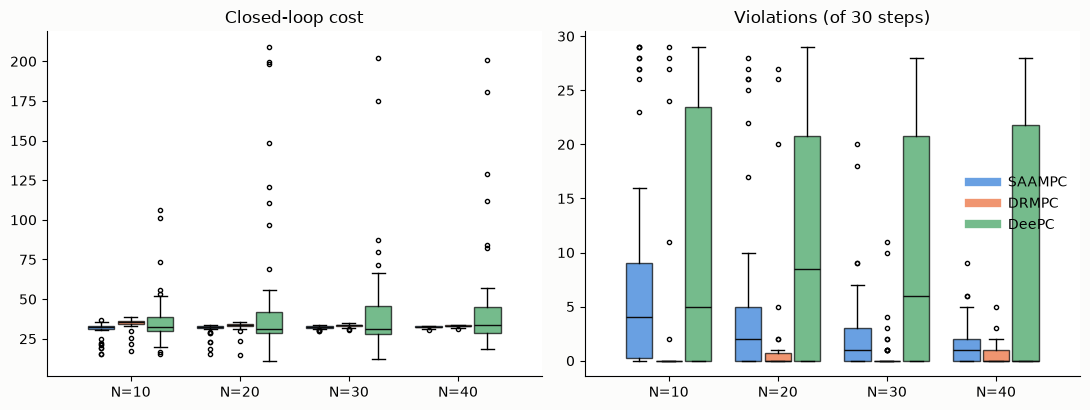

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="#fcfcfb")
positions = np.arange(len(SIZES))
for ax, column, title in [(axes[0], 0, "Closed-loop cost"), (axes[1], 1, f"Violations (of {STEPS} steps)")]:
    for k, name in enumerate(COLORS):
        data = [results[N][name][:, column] for N in SIZES]
        data = [d[~np.isnan(d)] for d in data]
        box = ax.boxplot(data, positions=positions + (k - 1) * 0.27, widths=0.24, patch_artist=True,
                         medianprops=dict(color="#0b0b0b"), flierprops=dict(markersize=3))
        for patch in box["boxes"]:
            patch.set(facecolor=COLORS[name], alpha=0.7)
        ax.plot([], [], color=COLORS[name], linewidth=6, alpha=0.7, label=name)
    ax.set_xticks(positions, [f"N={N}" for N in SIZES])
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Head to head: who won each trial

Each trial gives all methods the same data and noise, so comparing **within** a trial cancels the luck of the draw (common random numbers): Var(A − B) = Var(A) + Var(B) − 2 Cov(A, B), and shared noise makes Cov(A, B) large.

**Sign test.** For each trial, record whether DeePC did better, worse, or tied, and drop the ties. If the methods were equally good, better/worse would be a fair coin flip. The p-value says how surprising the observed split is under that coin flip. It ignores how *much* better, so it is robust to the pile of zero-violation trials.

**Thresholds.** A claim across all N runs 8 violation tests (4 N × 2 opponents), so the Bonferroni threshold is 0.05 / 8 ≈ 0.006. Running more tests gives more chances of a fluke.

In [8]:
from math import comb


def sign_test(better, worse):
    """Two-sided exact p-value that better/worse is a fair coin flip (ties already dropped)."""
    k, total = min(better, worse), better + worse
    return min(1.0, 2 * sum(comb(total, i) for i in range(k + 1)) / 2**total) if total else 1.0


OPPONENTS = ("SAAMPC", "DRMPC")
METRICS = {0: "cost", 1: "violations"}
head_to_head = {}  # (N, opponent, column) -> (DeePC better, tie, DeePC worse, p)
for N in SIZES:
    for other in OPPONENTS:
        for column in METRICS:
            d = results[N]["DeePC"][:, column] - results[N][other][:, column]
            d = d[~np.isnan(d)]
            better, tie, worse = np.sum(d < 0), np.sum(d == 0), np.sum(d > 0)
            head_to_head[N, other, column] = (better, tie, worse, sign_test(better, worse))

print("DeePC vs. opponent, per trial: better / tie / worse (sign test p)")
for N in SIZES:
    cells = []
    for other in OPPONENTS:
        for column, label in METRICS.items():
            b, t, w, p = head_to_head[N, other, column]
            cells.append(f"{label} vs {other}: {b:>2}/{t:>2}/{w:>2} (p={p:.3f})")
    print(f"N={N:<3} | " + " | ".join(cells))

DeePC vs. opponent, per trial: better / tie / worse (sign test p)
N=10  | cost vs SAAMPC: 24/ 0/26 (p=0.888) | violations vs SAAMPC: 19/ 8/23 (p=0.644) | cost vs DRMPC: 35/ 0/15 (p=0.007) | violations vs DRMPC:  4/16/30 (p=0.000)
N=20  | cost vs SAAMPC: 28/ 0/22 (p=0.480) | violations vs SAAMPC: 14/ 9/27 (p=0.060) | cost vs DRMPC: 30/ 0/20 (p=0.203) | violations vs DRMPC:  4/14/32 (p=0.000)
N=30  | cost vs SAAMPC: 27/ 0/23 (p=0.672) | violations vs SAAMPC: 15/ 9/26 (p=0.117) | cost vs DRMPC: 29/ 0/21 (p=0.322) | violations vs DRMPC:  6/18/26 (p=0.001)
N=40  | cost vs SAAMPC: 22/ 0/28 (p=0.480) | violations vs SAAMPC: 17/11/22 (p=0.522) | cost vs DRMPC: 23/ 0/27 (p=0.672) | violations vs DRMPC:  7/21/22 (p=0.008)


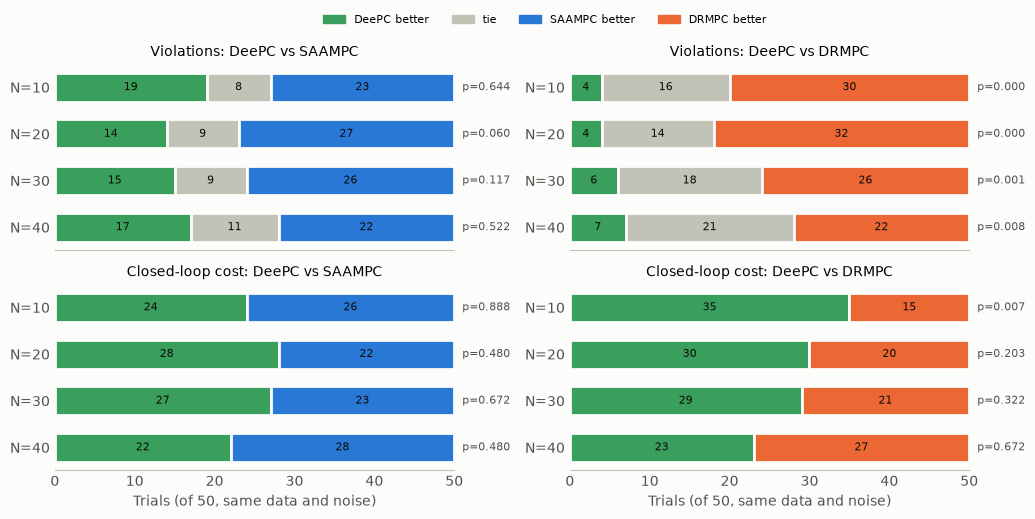

In [9]:
SURFACE, TIE, INK, MUTED = "#fcfcfb", "#c3c2b7", "#0b0b0b", "#52514e"
fig, axes = plt.subplots(2, 2, figsize=(11, 5.2), sharex=True, facecolor=SURFACE)
rows = [(1, "Violations"), (0, "Closed-loop cost")]
y = np.arange(len(SIZES))[::-1]  # N = 35 on top

for r, (column, metric) in enumerate(rows):
    for c, other in enumerate(OPPONENTS):
        ax = axes[r, c]
        ax.set_facecolor(SURFACE)
        for yi, N in zip(y, SIZES):
            better, tie, worse, p = head_to_head[N, other, column]
            left = 0
            for count, color in [(better, COLORS["DeePC"]), (tie, TIE), (worse, COLORS[other])]:
                if count:
                    ax.barh(yi, count, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=2)
                    if count >= 3:
                        ax.text(left + count / 2, yi, str(count), ha="center", va="center", fontsize=8, color=INK)
                left += count
            ax.text(TRIALS * 1.02, yi, f"p={p:.3f}", va="center", fontsize=8, color=MUTED)
        ax.set_yticks(y, [f"N={N}" for N in SIZES])
        ax.set_xlim(0, TRIALS)
        ax.set_title(f"{metric}: DeePC vs {other}", fontsize=10)
        ax.tick_params(length=0, colors=MUTED)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color(TIE)
for ax in axes[-1]:
    ax.set_xlabel(f"Trials (of {TRIALS}, same data and noise)", color=MUTED)

legend = {"DeePC better": COLORS["DeePC"], "tie": TIE,
          "SAAMPC better": COLORS["SAAMPC"], "DRMPC better": COLORS["DRMPC"]}
fig.legend([plt.Rectangle((0, 0), 1, 1, color=v) for v in legend.values()], legend.keys(),
           loc="upper center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 0.95, 0.95))
plt.show()

## Conclusions

To be written after running the notebook.